In [2]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import torch.nn as nn
import numpy as np
import os
import matplotlib
from matplotlib import animation 
from IPython.display import HTML 
import matplotlib.pyplot as plt
import copy
os.environ["MUJOCO_GL"] = "egl"
from dm_control import suite
device


device(type='cuda')

Training order
Collect roughly 1k–10k random-policy rollouts, with frames resized to 64×64.
Train V. Check it by eye: are the reconstructions recognizable?
Encode the whole dataset into z sequences.
Train M on those sequences with truncated BPTT, using fixed-length chunks. To check it, roll M forward from a real starting state with real actions, decode the predicted z's with V, and see whether the "imagined video" looks plausible.
Train C with CMA-ES:
Dream training: evaluate fitness entirely inside M. Raise the sampling temperature τ so the controller can't exploit flaws in the model. The paper discusses this, and it's a really important insight.
Real training: evaluate in the true environment. Comparing the two is a great experiment.
(Optional) Iterate: collect new data with the trained controller, retrain V and M, and repeat. Random policies often never reach interesting states, so the model never learns them.


Milestones
VAE reconstructions look right.
MDN-RNN NLL goes down, and open-loop dream videos stay plausible for 10+ steps.
Reward predicted by M correlates with the real reward.
A controller trained in the dream gets a nonzero real reward.

1. Collect random policy rollouts

In [3]:
# Inline video helper function
if os.environ.get('COLAB_NOTEBOOK_TEST', False):
  # We skip video generation during tests, as it is quite expensive.
  display_video = lambda *args, **kwargs: None
else:
  def display_video(frames, framerate=30):
    height, width, _ = frames[0].shape
    dpi = 70
    orig_backend = matplotlib.get_backend()
    matplotlib.use('Agg')  # Switch to headless 'Agg' to inhibit figure rendering.
    fig, ax = plt.subplots(1, 1, figsize=(width / dpi, height / dpi), dpi=dpi)
    matplotlib.use(orig_backend)  # Switch back to the original backend.
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.set_position([0, 0, 1, 1])
    im = ax.imshow(frames[0])
    def update(frame):
      im.set_data(frame)
      return [im]
    interval = 1000/framerate
    anim = animation.FuncAnimation(fig=fig, func=update, frames=frames,
                                   interval=interval, blit=True, repeat=False)
    plt.close(fig)
    return HTML(anim.to_html5_video())

In [4]:

random_state = np.random.RandomState(42)
# Load the cartpole swingup environment
env = suite.load(domain_name="cartpole", task_name="swingup", task_kwargs={'random': random_state})
# step with task, render, collect observations

#images need to be custom size, need to know which camera we are using
# Simulate episode with random actions
duration = 4  # Seconds
frames = []
ticks = []
rewards = []
observations = []

spec = env.action_spec()
time_step = env.reset()

while env.physics.data.time < duration:

  action = random_state.uniform(spec.minimum, spec.maximum, spec.shape)
  time_step = env.step(action)

  camera0 = env.physics.render(camera_id=0, height=64, width=64) # in pixels
  # camera1 = env.physics.render(camera_id=1, height=200, width=200)
  frames.append(camera0)
  rewards.append(time_step.reward)
  observations.append(copy.deepcopy(time_step.observation))
  ticks.append(env.physics.data.time)

html_video = display_video(frames, framerate=1./env.control_timestep())
html_video
# Show video and plot reward and observations



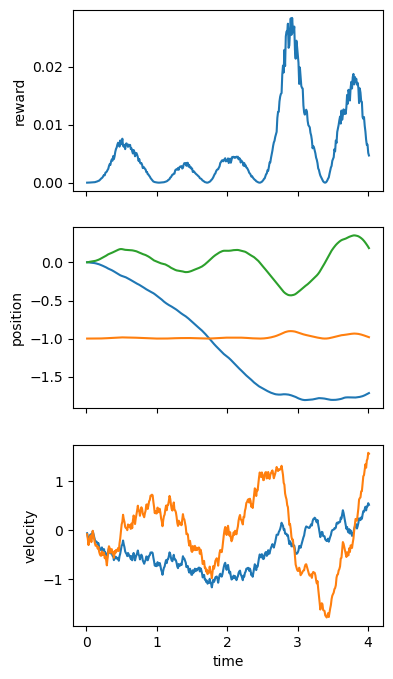

In [ ]:
%matplotlib inline
num_sensors = len(time_step.observation)

_, ax = plt.subplots(1 + num_sensors, 1, sharex=True, figsize=(4, 8))
ax[0].plot(ticks, rewards)
ax[0].set_ylabel('reward')
ax[-1].set_xlabel('time')

for i, key in enumerate(time_step.observation):
  data = np.asarray([observations[j][key] for j in range(len(observations))])
  ax[i+1].plot(ticks, data, label=key)
  ax[i+1].set_ylabel(key)

plt.show()

In [17]:
#collect 1k -10k episodes
# epsiode = 1000 steps 
# 10 seconds x 1000 episodes 
# action repeat 8, only save when action is taken 
# 125 frames per episode = 1000/8 


def collect_episodes(env, action_repeat = 8, num_episodes = 100):
    all_episodes = []
    for _ in range(num_episodes):
        episode = {}
        frames = []
        actions = []
        rewards = []
       
        spec = env.action_spec()
        time_step = env.reset()
        camera0 = env.physics.render(camera_id=0, height=64, width=64) # in pixels
        frames.append(camera0)
        while time_step.last() is False:
            rewards_tot = 0
            action = random_state.uniform(spec.minimum, spec.maximum, spec.shape)
            for _ in range(action_repeat):
                if time_step.last() == True:
                    break
                time_step = env.step(action)
                rewards_tot += time_step.reward
            # camera1 = env.physics.render(camera_id=1, height=200, width=200)
            
            camera0 = env.physics.render(camera_id=0, height=64, width=64) # in pixels
            actions.append(action)
            frames.append(camera0)
            rewards.append(rewards_tot)
        # append frames, actions , rewards 
        episode = {
            'frames' : np.array(frames, dtype = np.uint8),
            'rewards' : np.array(rewards, dtype = np.float32),
            'actions' : np.array(actions, dtype = np.float32),
        }

        all_episodes.append(episode)
    return all_episodes



In [19]:
data = collect_episodes(env, action_repeat = 8, num_episodes = 100)

In [27]:
data[0]['rewards'].shape

(125,)

In [ ]:
# os.makedirs('data/cartpole_swingup_episodes', exist_ok = True)

In [ ]:
# for i, episode in enumerate(data): # list of all episodes
    
#     np.savez_compressed(f'data/cartpole_swingup_episodes/episode_{i}', **episode)

In [ ]:
#load all epusides, concatenate the frames
# set aside 10 episodes for validation
# write a Dataset